# Метрики качества, переобучение, кросс-валидация

**Курс «Основы. Специалист по искусственному интеллекту» · Модуль 3. Машинное обучение**

Модель выдала ответы. Теперь нужно понять, полезны ли они на новых объектах и можно ли доверять полученной оценке. В этом материале мы последовательно сравним предсказания с известными ответами, увидим признаки переобучения и проверим модель на нескольких разбиениях данных.

Это учебный материал с выполненными примерами для занятия и самостоятельного чтения. **Заданий нет.** Перед каждой кодовой ячейкой описано, что она показывает, а после неё разобраны конструкции Python, методы библиотек и смысл результата. Формулы и математические выводы не используются.

Все данные небольшие и создаются внутри ноутбука. Загружать датасеты или обращаться к интернету при выполнении не требуется. Примеры классификации относятся к условной проверке обращений, а числовой пример — к прогнозу длительности обработки. Эти данные не описывают реальную организацию.

Сначала будут отдельные понятные примеры метрик, затем — сквозной пример оценки модели. Устройство алгоритмов, подробная предобработка и работа библиотек NumPy, Pandas и Matplotlib относятся к соседним темам; здесь мы поясняем используемый код в объёме, необходимом для чтения примеров.

## Как читать и запускать материал

Сохранённые результаты можно изучать без запуска Python. Для повторного выполнения выберите **Restart Kernel and Run All / «Перезапустить ядро и выполнить все ячейки»**. Выполнять ячейки следует сверху вниз: последующие примеры используют переменные из предыдущих. Ядро — работающий процесс Python, в памяти которого хранятся эти переменные.

Нужны Python и пакеты `numpy`, `pandas`, `matplotlib`, `scikit-learn`, а также среда Jupyter. Версии, на которых материал проверен, будут напечатаны в первой ячейке. Установка пакетов в ноутбуке не выполняется.

**Метрика качества** — числовой показатель, который вычисляют по известным правильным ответам и предсказаниям. Само число не объясняет, какие ошибки допустимы. Поэтому мы всегда уточняем задачу, нужное направление изменения метрики и данные, на которых она получена. В этом файле рассматриваются метрики обучения с учителем; оценка кластеризации и обучения с подкреплением требует других критериев.

Подключим инструменты для таблиц, рисунков, готовых моделей и оценки. Импорт только делает эти инструменты доступными в коде: обучение начнётся позднее. Настроим читаемый вид таблиц и рисунков и выведем версии библиотек, чтобы результат можно было воспроизвести в сопоставимой среде.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    make_scorer,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    GridSearchCV,
    GroupKFold,
    StratifiedKFold,
    TimeSeriesSplit,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 3)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Matplotlib:', matplotlib.__version__)
print('scikit-learn:', sklearn.__version__)

Python: 3.13.13
NumPy: 2.4.6
Pandas: 2.3.3
Matplotlib: 3.10.9
scikit-learn: 1.8.0


**Разбор кода.**

- `import` подключает модуль или пакет. Запись `import numpy as np` даёт ему короткое имя `np`; аналогично используются `pd` и `plt`. Точка в `matplotlib.pyplot` указывает вложенный модуль. `from ... import ...` подключает перечисленные инструменты непосредственно под их именами. Круглые скобки позволяют перенести длинный список импортов на несколько строк; запятые разделяют элементы.
- NumPy хранит массивы чисел; Pandas — таблицы; Matplotlib — рисунки. В `sklearn` находятся готовые модели и средства их проверки. `display` из IPython выводит таблицы в удобном для ноутбука виде. Назначение конкретных импортированных классов и функций раскрывается при первом использовании.
- `pd.set_option(...)` меняет настройку отображения. Строки в кавычках — текстовые значения; `12` и `3` — целые числа. Здесь показываем до 12 столбцов и три знака при отображении чисел. Хранимые числа при этом не округляются.
- `plt.rcParams` — набор настроек рисунков. Квадратные скобки выбирают настройку по текстовому ключу; `=` присваивает ей значение. Шрифт DejaVu Sans поддерживает русские подписи; `figure.dpi` задаёт плотность изображения.
- `print(...)` выводит текст и значения. Запятая между аргументами передаёт несколько значений. `sys.version` — строка с версией Python, метод `split()` разбивает её по пробельным символам, `[0]` выбирает первый фрагмент: отсчёт позиций начинается с нуля.
- `.__version__` — атрибут с версией пакета. Атрибут читается через точку; функция или метод вызывается с круглыми скобками. Подчёркивания в именах здесь являются частью имён, заданных библиотекой.

## 1. Качество классификации: какие ошибки скрывает одно число

### Правильные ответы и предсказания

Представим 20 обращений. У 18 обращений дополнительная проверка не нужна, у двух нужна. Известный ответ обозначим `0` или `1`: **класс 1 — требуется проверка**, класс 0 — обычная обработка. Класс 1 называется положительным: слово «положительный» обозначает выбранное событие, а не хорошую оценку.

Сравним две системы. Первая всегда отвечает «проверка не нужна». Вторая направляет на проверку оба нужных обращения и ещё два обычных. Предсказания здесь заданы вручную, чтобы сначала увидеть смысл оценки без обучения модели. Порядок объектов в правильных ответах и предсказаниях должен совпадать.

Создадим правильные ответы и два набора предсказаний одинаковой длины. Нумерация обращений будет начинаться с единицы для удобства чтения таблицы, а выбор позиций в массивах Python по-прежнему начинается с нуля. Последние две строки содержат обращения, которым действительно нужна проверка.

In [2]:
true_labels = np.array([0] * 18 + [1] * 2)
default_predictions = np.zeros(len(true_labels), dtype=int)
review_predictions = np.zeros(len(true_labels), dtype=int)
review_predictions[[2, 7, 18, 19]] = 1

classification_example = pd.DataFrame({
    'Обращение': range(1, len(true_labels) + 1),
    'Нужна проверка: факт': true_labels,
    'Всегда класс 0': default_predictions,
    'Отправка на проверку': review_predictions,
})
display(classification_example)

,Обращение,Нужна проверка: факт,Всегда класс 0,Отправка на проверку
0,1,0,0,0
1,2,0,0,0
2,3,0,0,1
3,4,0,0,0
4,5,0,0,0
5,6,0,0,0
6,7,0,0,0
7,8,0,0,1
8,9,0,0,0
9,10,0,0,0


**Разбор кода и результата.**

- `true_labels`, `default_predictions` и `review_predictions` — имена переменных. `=` сохраняет результат справа под именем слева. Имена написаны латиницей; заголовки таблиц остаются русскими.
- `[0]` — список с одним нулём. Для списков `* 18` повторяет элементы 18 раз, а `+` соединяет два списка. Поэтому `[0] * 18 + [1] * 2` содержит 18 нулей и две единицы. `np.array(...)` превращает список в массив NumPy.
- `len(...)` возвращает число элементов. `np.zeros(...)` создаёт массив нулей нужной длины; именованный аргумент `dtype=int` задаёт целочисленный тип. Именованный аргумент записывается как `имя=значение` внутри вызова.
- `review_predictions[[2, 7, 18, 19]] = 1` меняет четыре выбранные позиции. Двойные квадратные скобки здесь означают обращение к массиву со списком позиций: это обращения 3, 8, 19 и 20.
- В `{...}` записан словарь: ключ слева от двоеточия станет названием столбца, значение справа — его содержимым. `pd.DataFrame(...)` создаёт таблицу из этого словаря. Все столбцы должны иметь согласованную длину.
- `range(1, len(true_labels) + 1)` задаёт последовательность от 1 до 20: правая граница `range` не включается. При вычислении числа `+ 1` означает обычное сложение. `display(...)` показывает таблицу.

Первая система пропускает все нужные проверки. Вторая не пропускает их, но создаёт две лишние проверки. Уже по таблице видно, что одинаковое количество ошибок ещё не означает одинаковую полезность.

### Матрица ошибок

Матрица ошибок группирует объекты по сочетанию факта и предсказания. В нашей договорённости строки соответствуют правильным ответам, столбцы — предсказаниям. При порядке классов `0, 1` верхняя левая ячейка содержит верно распознанные обычные обращения (**TN**), верхняя правая — лишние проверки (**FP**), нижняя левая — пропущенные нужные проверки (**FN**), нижняя правая — найденные нужные проверки (**TP**).

Обозначения полезны для чтения документации, но оценивать результат можно и по русским названиям ошибок. Всегда проверяйте подписи осей: в других программах расположение строк и столбцов может отличаться.

Построим две матрицы рядом. Явно зададим порядок классов и подпишем оси. Важны числа внутри клеток: оттенок помогает ориентироваться, но не заменяет подсчёт пропусков и лишних проверок.

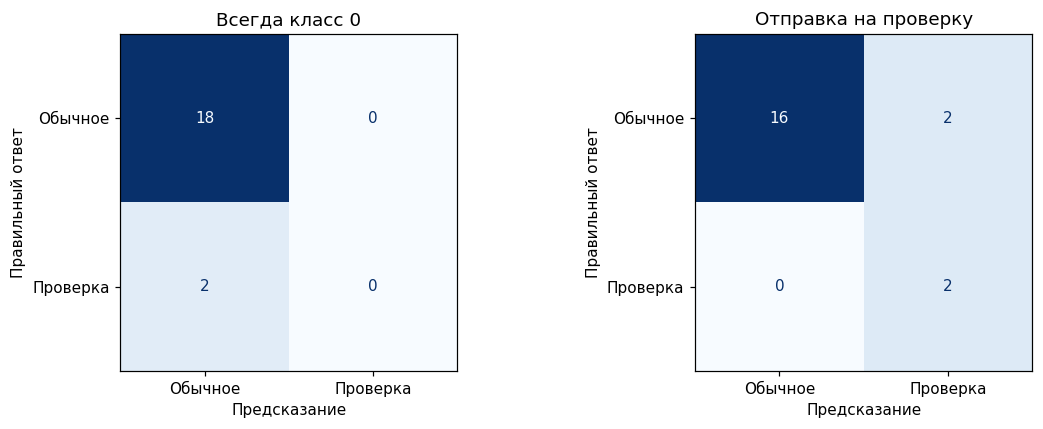

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
prediction_sets = [default_predictions, review_predictions]
titles = ['Всегда класс 0', 'Отправка на проверку']

for ax, predictions, title in zip(axes, prediction_sets, titles):
    ConfusionMatrixDisplay.from_predictions(
        true_labels,
        predictions,
        labels=[0, 1],
        display_labels=['Обычное', 'Проверка'],
        cmap='Blues',
        colorbar=False,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel('Предсказание')
    ax.set_ylabel('Правильный ответ')

fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `plt.subplots(1, 2, figsize=(11, 4))` создаёт один ряд из двух графиков. Возвращаются два значения: рисунок `fig` и набор областей рисования `axes`. Запись `fig, axes = ...` распределяет их по двум переменным. `(11, 4)` — кортеж размеров рисунка в дюймах.
- `prediction_sets` и `titles` — списки. `zip(...)` последовательно объединяет элементы трёх наборов по одинаковой позиции. Цикл `for ... in ...:` берёт очередную тройку и выполняет строки с отступом для выбранного графика, предсказаний и заголовка. Двоеточие начинает блок; отступы показывают его границы.
- `ConfusionMatrixDisplay.from_predictions(...)` сам считает матрицу по двум массивам и рисует её. Сначала передаётся факт, затем предсказание. `labels=[0, 1]` закрепляет порядок; `display_labels` задаёт текст вместо чисел. `cmap='Blues'` выбирает палитру, `colorbar=False` отключает цветовую шкалу. `False` — логическое значение «нет».
- `ax=ax` передаёт выбранную область рисования. Методы `set_title`, `set_xlabel`, `set_ylabel` задают заголовок и подписи осей. `fig.tight_layout()` размещает элементы с учётом подписей; `plt.show()` выводит рисунок.

У первой системы 18 верных обычных ответов и два пропуска. У второй — 16 верных обычных ответов, две лишние проверки и две найденные нужные проверки. Обе системы ошиблись на двух объектах, но ошибки различаются по последствиям.

### Accuracy, precision, recall, F1 и balanced accuracy

| Метрика | Что сообщает в нашем примере | Направление |
|---|---|---|
| Accuracy | Какая доля всех обращений получила правильный класс | Больше — лучше |
| Precision класса 1 | Какая доля отправленных на проверку действительно нуждалась в ней | Больше — лучше |
| Recall класса 1 | Какая доля всех нужных проверок была найдена | Больше — лучше |
| F1 класса 1 | Совместная оценка precision и recall, снижающаяся при слабом значении одного из них | Больше — лучше |
| Balanced accuracy | Recall, усреднённый с одинаковым весом для каждого класса | Больше — лучше |

Значения этих метрик находятся между 0 и 1, где 1 означает лучший результат по выбранному критерию. Высокая accuracy может получиться за счёт частого класса. Precision важна при ограниченной возможности проверять лишнее; recall — когда опасно пропустить нужную проверку. F1 не учитывает стоимость ошибок и число верных ответов класса 0 напрямую, поэтому автоматически выбирать её для любой задачи нельзя.

Если система никого не направила на проверку, precision невозможно содержательно посчитать: нет ни одного такого предсказания. В коде явно зададим для этой ситуации служебное значение 0. Это соглашение об отображении, а не доказательство, что математически определённая precision равна нулю.

Вычислим одинаковый набор метрик для обеих систем. Небольшая функция соберёт показатели в словарь, чтобы последующие примеры использовали те же настройки положительного класса и обработки пустых случаев. Затем сравним две строки в одной таблице.

In [4]:
def classification_metrics(actual, predicted):
    return {
        'Accuracy': accuracy_score(actual, predicted),
        'Precision (класс 1)': precision_score(
            actual, predicted, pos_label=1, zero_division=0
        ),
        'Recall (класс 1)': recall_score(
            actual, predicted, pos_label=1, zero_division=0
        ),
        'F1 (класс 1)': f1_score(
            actual, predicted, pos_label=1, zero_division=0
        ),
        'Balanced accuracy': balanced_accuracy_score(actual, predicted),
    }

comparison = pd.DataFrame({
    'Всегда класс 0': classification_metrics(true_labels, default_predictions),
    'Отправка на проверку': classification_metrics(true_labels, review_predictions),
}).T
display(comparison)

,Accuracy,Precision (класс 1),Recall (класс 1),F1 (класс 1),Balanced accuracy
Всегда класс 0,0.9,0.0,0.0,0.000,0.500
Отправка на проверку,0.9,0.5,1.0,0.667,0.944


**Разбор кода и результата.**

- `def classification_metrics(actual, predicted):` определяет функцию с двумя параметрами. При вызове `actual` получает правильные ответы, `predicted` — предсказания. Отступ объединяет строки тела функции; `return` возвращает словарь результатов вызывающему коду.
- Функции `accuracy_score`, `precision_score`, `recall_score`, `f1_score` и `balanced_accuracy_score` из scikit-learn вычисляют одноимённые показатели. Во всех вызовах факт идёт первым, предсказание вторым. `pos_label=1` явно выбирает класс события; `zero_division=0` задаёт результат в случае отсутствующего знаменателя, например когда ни один объект не предсказан как класс 1.
- `classification_metrics(...)` вызывается дважды с разными предсказаниями. Внешний словарь именует две системы. `pd.DataFrame(...)` собирает результаты, а атрибут `.T` меняет местами строки и столбцы: системы оказываются в строках. `display(...)` показывает таблицу.

Accuracy равна **0,9 у обеих систем**. У постоянного ответа recall класса 1 равна 0, а balanced accuracy — 0,5. У системы с проверками recall равна 1, precision — 0,5: все нужные проверки найдены, но половина направлений оказалась лишней. F1 учитывает оба этих свойства. По одной accuracy различить системы не удалось.

Высокая recall сама по себе тоже недостаточна: если направить на проверку вообще всё, пропусков не будет, но нагрузка на проверяющих резко увеличится. Выбор основного показателя должен следовать из назначения системы.

### Несколько классов: как читать усреднение

Если классов больше двух, precision, recall и F1 можно показать отдельно для каждого класса. Для строки конкретного класса он временно рассматривается как интересующее событие, остальные — как всё остальное. **Support** — количество объектов этого класса среди правильных ответов.

**Macro average** даёт каждому классу одинаковое влияние на итог. **Weighted average** учитывает число объектов каждого класса, поэтому частый класс влияет сильнее. Строка усреднения не заменяет просмотр отдельных классов. В следующем коротком примере редкий класс распознаётся хуже, и это важно сохранить в отчёте.

Создадим восемь условных ответов с тремя классами и получим готовый отчёт. Нам нужен табличный результат, поэтому попросим библиотеку вернуть словарь вместо текстового отчёта. Названия классов передадим в том же порядке, что и их числовые коды.

In [5]:
multiclass_actual = [0, 0, 0, 0, 1, 1, 2, 2]
multiclass_predicted = [0, 0, 0, 0, 1, 0, 1, 0]
report = classification_report(
    multiclass_actual,
    multiclass_predicted,
    labels=[0, 1, 2],
    target_names=['Обычное', 'Срочное', 'Техническое'],
    output_dict=True,
    zero_division=0,
)
report_rows = ['Обычное', 'Срочное', 'Техническое', 'macro avg', 'weighted avg']
display(pd.DataFrame(report).T.loc[report_rows])

,precision,recall,f1-score,support
Обычное,0.667,1.000,0.800,4.0
Срочное,0.500,0.500,0.500,2.0
Техническое,0.000,0.000,0.000,2.0
macro avg,0.389,0.500,0.433,8.0
weighted avg,0.458,0.625,0.525,8.0


**Разбор кода и результата.**

- Два списка содержат правильные и предсказанные коды классов. `classification_report(...)` получает их в этом порядке. `labels` закрепляет коды, `target_names` — соответствующие им названия. `output_dict=True` возвращает словарь; `True` означает «да». `zero_division=0` задаёт такое же соглашение для неопределённых показателей, как раньше.
- `report_rows` — список строк, которые хотим показать. `pd.DataFrame(report).T` превращает отчёт в таблицу с классами по строкам. `.loc[report_rows]` выбирает строки по их названиям, в заданном порядке. `display(...)` выводит таблицу.

Для «Технического» класса recall равна 0: ни один из двух таких объектов не найден. Precision в этой строке показана как 0 по нашему соглашению, поскольку модель вообще не предсказала этот класс. Обычные обращения распознаны лучше и встречаются чаще, поэтому weighted F1 выше macro F1. Значения `support` в строках усреднения показывают общее число объектов отчёта.

### Оценка уверенности и порог решения

Модель может возвращать не только готовый класс, но и числовую оценку принадлежности к классу 1. Порог превращает её в решение: в нашем примере оценки не ниже выбранного порога отправляются на проверку. Изменение порога меняет precision и recall, хотя сами оценки остаются прежними.

Оценку нельзя автоматически считать достоверной вероятностью реального события. Например, число 0,9 само по себе не гарантирует 90% правильных ответов среди подобных объектов. Здесь значения заданы вручную, чтобы отделить изменение правила решения от обучения модели. Подбирать рабочий порог можно на данных разработки; финальную проверочную выборку для этого не используют.

Присвоим каждому из прежних 20 обращений одну и ту же фиксированную оценку во всех трёх вариантах. Сравним пороги 0,2, 0,5 и 0,8: сколько обращений уйдёт на проверку, сколько проверок будет лишними и сколько нужных проверок окажется пропущено.

In [6]:
positive_scores = np.array([
    0.05, 0.10, 0.75, 0.15, 0.20, 0.05, 0.30, 0.65, 0.10, 0.25,
    0.10, 0.20, 0.05, 0.15, 0.30, 0.20, 0.10, 0.05, 0.55, 0.90,
])
threshold_rows = []

for threshold in [0.2, 0.5, 0.8]:
    decisions = (positive_scores >= threshold).astype(int)
    row = {
        'Порог': threshold,
        'Направлено на проверку': int(decisions.sum()),
        'Лишние проверки': int(((true_labels == 0) & (decisions == 1)).sum()),
        'Пропущенные проверки': int(((true_labels == 1) & (decisions == 0)).sum()),
    }
    row.update(classification_metrics(true_labels, decisions))
    threshold_rows.append(row)

display(pd.DataFrame(threshold_rows).set_index('Порог'))

,Направлено на проверку,Лишние проверки,Пропущенные проверки,Accuracy,Precision (класс 1),Recall (класс 1),F1 (класс 1),Balanced accuracy
Порог,,,,,,,,
0.2,10,8,0,0.60,0.2,1.0,0.333,0.778
0.5,4,2,0,0.90,0.5,1.0,0.667,0.944
0.8,1,0,1,0.95,1.0,0.5,0.667,0.750


**Разбор кода и результата.**

- `np.array(...)` создаёт массив оценок в порядке прежних обращений. Числа с точкой, например `0.05`, — числа с дробной частью. `threshold_rows = []` создаёт пустой список для накопления строк.
- Цикл `for threshold in [...]` перебирает три порога. Сравнение `positive_scores >= threshold` выполняется для каждого элемента массива и возвращает логические значения. `.astype(int)` превращает `True` в 1, а `False` в 0.
- `decisions.sum()` складывает нули и единицы, поэтому считает направления на проверку. `==` проверяет равенство, в отличие от присваивания `=`. `(true_labels == 0) & (decisions == 1)` выбирает объекты, у которых одновременно выполнены оба условия. `&` означает поэлементное «и» для массивов; каждое условие заключено в скобки. Метод `sum()` считает выбранные объекты. `int(...)` переводит результат в обычное целое число Python.
- `row` — словарь одной строки. `classification_metrics(...)` вычисляет уже знакомые показатели. `row.update(...)` дополняет словарь этими показателями, `threshold_rows.append(row)` добавляет готовую строку в список.
- `pd.DataFrame(...)` собирает строки; `set_index('Порог')` делает порог названием строки. `display(...)` показывает итог.

При пороге 0,5 получаем прежнюю систему с двумя лишними проверками. При 0,8 остаётся одна правильная проверка: precision увеличилась до 1, но recall снизилась до 0,5. Снижение порога до 0,2 добавило лишние проверки и в данном наборе не нашло новых нужных: recall уже была равна 1. Сдвиг порога не обязан улучшать обе метрики.

### Ранжирование: ROC-AUC и Average Precision

Иногда важно оценить, ставит ли система нужные проверки выше обычных в отсортированном списке. **ROC-AUC** характеризует такое ранжирование по всем возможным порогам; больше — лучше, диапазон от 0 до 1. Значение около 0,5 соответствует уровню случайного ранжирования в среднем. Это не доля верно определённых классов.

**Average Precision (AP)** обобщает сочетания precision и recall при просмотре списка от более высоких оценок к более низким. Больше — лучше. При редком классе 1 полезно смотреть на precision–recall: высокая ROC-AUC сама по себе не говорит, что лишних проверок будет мало. AP зависит и от состава оцениваемого набора, поэтому нельзя напрямую сравнивать результаты на выборках с разной долей класса 1.

В библиотеке AP имеет собственный способ обобщения точек; это **не то же самое**, что площадь, рассчитанная под precision–recall-кривой методом трапеций. Поэтому будем подписывать её именно `Average Precision (AP)`. Обе оценки ранжирования требуют наличия нужных классов; в частности, ROC-AUC для бинарной задачи не определена, если в правильных ответах только один класс.

Передадим функциям исходные оценки, а не готовые нули и единицы. Рядом построим ROC-кривую и precision–recall-кривую по тем же данным. Каждая из них показывает варианты работы при изменении порога; конкретный рабочий порог всё равно нужно выбирать отдельно.

ROC-AUC: 0.944
Average Precision (AP): 0.75


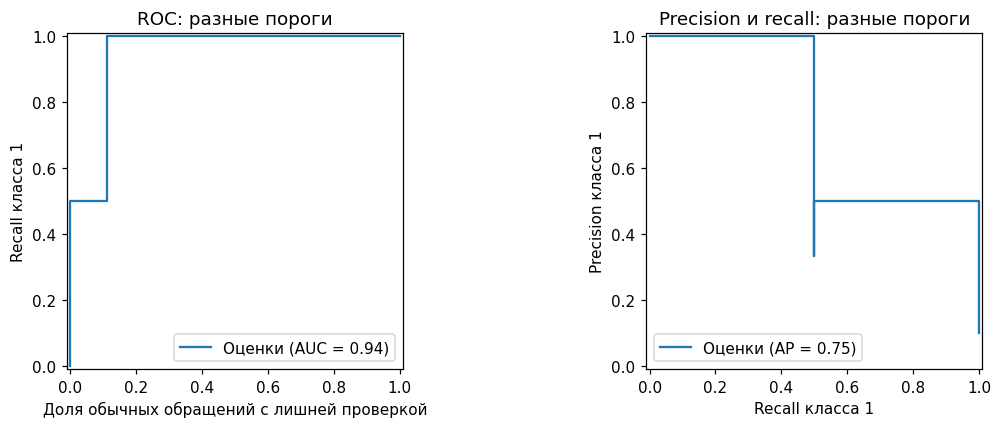

In [7]:
print('ROC-AUC:', round(roc_auc_score(true_labels, positive_scores), 3))
print('Average Precision (AP):', round(average_precision_score(true_labels, positive_scores), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(true_labels, positive_scores, ax=axes[0], name='Оценки')
PrecisionRecallDisplay.from_predictions(true_labels, positive_scores, ax=axes[1], name='Оценки')
axes[0].set_title('ROC: разные пороги')
axes[0].set_xlabel('Доля обычных обращений с лишней проверкой')
axes[0].set_ylabel('Recall класса 1')
axes[1].set_title('Precision и recall: разные пороги')
axes[1].set_xlabel('Recall класса 1')
axes[1].set_ylabel('Precision класса 1')
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `roc_auc_score(...)` и `average_precision_score(...)` получают правильные ответы и оценки класса 1. При метках 0 и 1 единица используется как положительный класс. Массив `positive_scores` передаётся без применения порога. `round(..., 3)` округляет только вывод до трёх знаков; `print(...)` печатает значения.
- `plt.subplots(...)` создаёт два графика; `axes[0]` и `axes[1]` выбирают их по позиции. `RocCurveDisplay.from_predictions(...)` строит ROC-кривую, `PrecisionRecallDisplay.from_predictions(...)` — precision–recall-кривую. У этих двух разных классов одинаковое имя метода `from_predictions`. `ax` задаёт область рисования, `name` — имя линии в легенде.
- Методы `set_title`, `set_xlabel`, `set_ylabel` подписывают рисунки. `tight_layout()` располагает их, `plt.show()` выводит результат.

Оценки хорошо поднимают нужные проверки вверх списка, поэтому ROC-AUC высокая. Однако два обычных обращения получили оценки выше одного из нужных. Это отражается в AP и в снижении precision при расширении списка проверок. Ни один из двух показателей не указывает автоматически, сколько сотрудников потребуется для обработки очереди.

## 2. Качество числового прогноза

В регрессии ответ — число, например длительность обработки обращения в минутах. Здесь важно величину ошибки выражать в понятных единицах и отличать небольшие отклонения от отдельных крупных промахов.

| Метрика | Как читать | Направление |
|---|---|---|
| MAE | Среднее отклонение по величине без учёта знака; в нашем примере — в минутах | Меньше — лучше, 0 — точный прогноз |
| RMSE | Ошибка в тех же единицах, более чувствительная к крупным промахам | Меньше — лучше, 0 — точный прогноз |
| R² | Сравнение с ориентиром, который выдаёт среднее фактических ответов оцениваемого набора | Больше — лучше, 1 — точный прогноз |

Для непостоянных фактических ответов R² равна 0 у указанного ориентира и может быть отрицательной у плохого прогноза. **R² не является процентом точности** и не обязана лежать между 0 и 1. Если все фактические ответы одинаковы, возникают особые случаи; здесь мы их не используем. Ориентир в определении R² нужен для интерпретации метрики: это не предложение получать рабочие предсказания из неизвестных будущих ответов.

Возьмём шесть известных длительностей и три набора прогнозов. Первые два совпадают почти полностью; во втором изменён только последний прогноз, в котором появляется крупная ошибка. Третий вариант постоянно выдаёт завышенное значение. Это позволит увидеть разные реакции метрик.

In [8]:
actual_minutes = np.array([10, 20, 30, 40, 50, 60])
regression_predictions = {
    'Небольшие отклонения': np.array([12, 18, 33, 37, 49, 61]),
    'Один крупный промах': np.array([12, 18, 33, 37, 49, 110]),
    'Всегда 100 минут': np.full(len(actual_minutes), 100.0),
}

regression_table = pd.DataFrame(regression_predictions)
regression_table.insert(0, 'Факт, минуты', actual_minutes)
display(regression_table)

,"Факт, минуты",Небольшие отклонения,Один крупный промах,Всегда 100 минут
0,10,12,12,100.0
1,20,18,18,100.0
2,30,33,33,100.0
3,40,37,37,100.0
4,50,49,49,100.0
5,60,61,110,100.0


**Разбор кода и результата.**

- `np.array(...)` создаёт массив правильных ответов и массивы прогнозов. `regression_predictions` — словарь, где каждому названию соответствует свой массив. Одинаковая позиция во всех массивах относится к одному обращению.
- `np.full(len(actual_minutes), 100.0)` создаёт массив указанной длины, целиком заполненный одним значением. `len(...)` получает длину массива; `100.0` записано как число с дробной частью, хотя дробная часть равна нулю.
- `pd.DataFrame(...)` делает каждый элемент словаря столбцом таблицы. `regression_table.insert(0, 'Факт, минуты', actual_minutes)` вставляет столбец в позицию 0 с указанным именем и содержимым. Этот метод меняет существующую таблицу. `display(...)` выводит её.

Сравниваем именно прогнозы с фактами, а не прогнозы между собой. Ошибка 110 вместо 60 — завышение на 50 минут; знак завышения исчезает в MAE и RMSE. Чтобы отличать систематическое завышение от занижения, дополнительно смотрят на сами отклонения.

Посчитаем MAE, RMSE и R² для каждого столбца прогнозов. Объекты и их порядок оставим прежними. Сравнение будет показывать влияние одного крупного промаха, а не влияние разных наборов обращений.

In [9]:
regression_rows = []
for name, predicted_minutes in regression_predictions.items():
    regression_rows.append({
        'Прогноз': name,
        'MAE, минуты': mean_absolute_error(actual_minutes, predicted_minutes),
        'RMSE, минуты': root_mean_squared_error(actual_minutes, predicted_minutes),
        'R²': r2_score(actual_minutes, predicted_minutes),
    })

display(pd.DataFrame(regression_rows).set_index('Прогноз'))

,"MAE, минуты","RMSE, минуты",R²
Прогноз,,,
Небольшие отклонения,2.000,2.160,0.984
Один крупный промах,10.167,20.522,-0.444
Всегда 100 минут,65.000,67.206,-14.486


**Разбор кода и результата.**

- `regression_rows = []` создаёт пустой список. `.items()` у словаря возвращает пары «ключ, значение». Цикл `for name, predicted_minutes in ...` распаковывает очередную пару в название и массив прогнозов.
- `mean_absolute_error(...)`, `root_mean_squared_error(...)` и `r2_score(...)` вычисляют MAE, RMSE и R². В каждом случае первый аргумент — правильные ответы, второй — прогнозы.
- `.append({...})` добавляет словарь одной строки в список. `pd.DataFrame(...)` собирает строки, `.set_index('Прогноз')` переносит названия прогнозов в индекс, `display(...)` показывает таблицу.

У первого прогноза MAE равна 2 минутам. При одном крупном промахе растут обе ошибки, особенно RMSE. У постоянного прогноза R² отрицательная: он хуже ориентира из определения метрики. Большая MAE не всегда означает, что каждый прогноз ошибочен именно на эту величину: это обобщение по набору объектов, а не характеристика каждого обращения.

Сравнивать ошибки в минутах и, например, в рублях по одному числу нельзя. Даже для одинаковой задачи оценку нужно привязывать к конкретному проверочному набору и условиям применения.

## 3. Разделение данных до выбора модели

### Три роли данных

Далее будем обучать готовую модель на небольшом искусственном наборе. В нём есть числовые сигналы и известный бинарный ответ. Не все сигналы полезны, а часть меток специально содержит шум. Мы не изучаем устройство алгоритма: модель нужна как инструмент, на котором видны ошибки оценки.

| Набор | Для чего используется | Какое решение можно принимать по результату |
|---|---|---|
| Обучающая часть, train | Подбор внутренних настроек модели по примерам | Научить модель |
| Валидационная часть, validation | Сравнение вариантов и настроек | Выбрать вариант для дальнейшей проверки |
| Финальная отложенная часть, test | Проверка после завершения выбора | Сообщить итоговую оценку |

Первые две роли вместе назовём **данными разработки** (`dev`). Сначала отложим финальный test, затем разделим dev для наглядного одиночного сравнения. Позже заменим это одиночное сравнение кросс-валидацией внутри dev. Финальную часть не передаём ни в обучение, ни в выбор настроек и не смотрим её метрики до конца.

Разбиение — не просто технический вызов. Если одни и те же клиенты попадают в обе части или будущая информация помогает предсказывать прошлое, оценка может оказаться завышенной. Здесь сначала предположим, что строки — независимые объекты; специальные случаи разберём отдельно.

Создадим 400 объектов с восемью условными числовыми сигналами. Названия сигналов не имеют прикладного смысла: это учебные признаки. Добавим несколько пропусков в первый столбец, чтобы далее проверить важное правило: подготовка данных должна обучаться заново внутри каждого разбиения вместе с моделью.

In [10]:
raw_features, raw_target = make_classification(
    n_samples=400,
    n_features=8,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.8, 0.2],
    flip_y=0.12,
    class_sep=0.9,
    random_state=42,
)
feature_names = [f'signal_{number}' for number in range(1, 9)]
features = pd.DataFrame(raw_features, columns=feature_names)
target = pd.Series(raw_target, index=features.index, name='needs_review')

rng = np.random.default_rng(12)
missing_positions = rng.choice(len(features), size=24, replace=False)
features.loc[missing_positions, 'signal_1'] = np.nan

display(features.head())
print('Число объектов:', len(features))
print('Пропусков в первом сигнале:', features['signal_1'].isna().sum())

,signal_1,signal_2,signal_3,signal_4,signal_5,signal_6,signal_7,signal_8
0,0.984,-0.219,1.164,0.234,-0.035,-0.214,1.551,-0.998
1,NaN,-1.064,1.918,0.514,-1.531,-0.334,0.572,-0.062
2,-1.002,0.770,1.595,-2.042,0.208,-0.281,-0.247,-0.682
3,0.334,1.048,0.537,0.077,-0.952,-0.155,0.258,-1.242
4,0.382,-0.073,1.013,-0.349,-0.349,0.430,-0.322,2.077


Число объектов: 400
Пропусков в первом сигнале: 24


**Разбор кода и результата.**

- `make_classification(...)` генерирует небольшой набор прямо в памяти. `n_samples` задаёт число объектов, `n_features` — число признаков, `n_informative` — число исходных полезных сигналов, `n_redundant=0` отключает их дополнительные линейные комбинации. `n_clusters_per_class=1` задаёт простой вариант генерации классов.
- `weights=[0.8, 0.2]` задаёт исходное соотношение классов. `flip_y=0.12` делает часть назначений случайными, добавляя шум; это не означает, что ровно 12% итоговых меток обязательно изменятся. `class_sep` управляет разделимостью сгенерированных классов. `random_state=42` закрепляет воспроизводимость генерации, а не гарантирует качество модели. Функция возвращает два массива, которые распределяются по переменным слева от `=`.
- `[f'signal_{number}' for number in range(1, 9)]` — списковое включение: короткая запись цикла, создающего список. `range(1, 9)` даёт числа 1–8; `f'...'` — форматируемая строка, в которой `{number}` подставляет текущее значение.
- `pd.DataFrame(..., columns=feature_names)` задаёт имена столбцов. `pd.Series(...)` создаёт один именованный столбец ответов; `index=features.index` сохраняет совпадающие идентификаторы строк. Атрибут `.index` содержит эти идентификаторы.
- `np.random.default_rng(12)` создаёт отдельный генератор случайных чисел с фиксированным начальным значением. Его метод `choice(...)` выбирает 24 позиции; `replace=False` запрещает повторять позицию. `.loc[строки, столбец]` присваивает выбранным ячейкам `np.nan` — маркер пропуска. Здесь индекс таблицы совпадает с позициями строк, поэтому выбранные числа подходят для `.loc`.
- `head()` показывает первые пять строк, `display(...)` выводит таблицу. `features['signal_1']` выбирает столбец; `isna()` отмечает пропуски, `sum()` считает их, `len(...)` считает строки. `print(...)` выводит итоговые числа.

Набор создан один раз, до разбиения. Результаты последующих сравнений относятся только к этому искусственному примеру и не подтверждают качество модели в реальной работе.

Отложим 20% объектов для финальной проверки. От оставшихся данных выделим четверть для текущей валидации: это ещё 20% исходного набора. Сохраним примерное соотношение классов и проверим отсутствие общих идентификаторов между частями. Такая проверка подтверждает отсутствие общих строк; независимость реальных объектов она сама по себе не доказывает.

In [11]:
X_dev, X_final, y_dev, y_final = train_test_split(
    features, target, test_size=0.2, stratify=target, random_state=31
)
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=11
)

assert set(X_dev.index).isdisjoint(X_final.index)
assert set(X_fit.index).isdisjoint(X_validation.index)

split_overview = pd.DataFrame({
    'Часть': ['Обучение', 'Валидация', 'Финальная проверка'],
    'Число объектов': [len(X_fit), len(X_validation), len(X_final)],
})
display(split_overview)
print('Общих идентификаторов между частями нет.')

,Часть,Число объектов
0,Обучение,240
1,Валидация,80
2,Финальная проверка,80


Общих идентификаторов между частями нет.


**Разбор кода и результата.**

- `train_test_split(...)` одновременно разделяет признаки и ответы, сохраняя их соответствие. При двух входах возвращаются четыре результата: признаки первой части, признаки второй части, ответы первой части, ответы второй части. `X` в именах обозначает признаки, `y` — ответы.
- `test_size=0.2` задаёт долю второй части, `0.25` во втором вызове — долю уже от `dev`. `stratify=...` просит сохранить примерно одинаковые доли классов. `random_state` закрепляет перемешивание. Разные фиксированные числа относятся к двум разным операциям.
- `set(...)` создаёт множество уникальных значений. `.isdisjoint(...)` проверяет, что с другим набором нет общих элементов. `assert` требует истинности условия и остановит выполнение при нарушении. Индексы наследуются от исходной таблицы и позволяют отследить строки после перемешивания.
- `pd.DataFrame(...)` создаёт обзор по длинам частей; `len(...)` считает строки. `display(...)` и `print(...)` выводят результаты.

Получились 240 объектов обучения, 80 валидации и 80 финальной проверки. Для разработки доступны 320 объектов. Имена `X_final` и `y_final` пока только хранят отложенную часть; её качество не вычислялось. Использование меток для стратифицированного разбиения не является подбором модели по итоговой метрике.

### Простой ориентир — baseline

Перед сравнением обучаемых вариантов полезно оценить простой способ ответа. **Baseline** — исходный ориентир: например, всегда выдавать самый частый класс обучающей части. Он помогает заметить ситуацию, когда сложная модель даёт красивую accuracy, но почти не решает интересующую задачу.

В сквозном примере основной метрикой заранее выберем **F1 класса 1**: хотим учитывать и пропуски, и лишние проверки. Это учебный выбор, а не универсальное решение. Остальные метрики будем показывать для понимания ошибок. Для всех моделей дальше используем стандартный метод `predict`; настройкой порога в сквозном примере не занимаемся.

Обучим готовый `DummyClassifier`, который запоминает самый частый класс, и оценим его на текущей валидационной части. Он получает признаки только ради общего интерфейса scikit-learn; закономерности в их значениях при этой стратегии не ищет.

In [12]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_fit, y_fit)
baseline_predictions = baseline.predict(X_validation)

display(pd.DataFrame(
    [classification_metrics(y_validation, baseline_predictions)],
    index=['Самый частый класс'],
))

,Accuracy,Precision (класс 1),Recall (класс 1),F1 (класс 1),Balanced accuracy
Самый частый класс,0.775,0.0,0.0,0.0,0.5


**Разбор кода и результата.**

- `DummyClassifier(strategy='most_frequent')` создаёт объект простого классификатора. Это вызов класса: результат сохраняется в `baseline`. Строковое значение стратегии задаёт постоянный ответ самым частым классом.
- `fit(X_fit, y_fit)` подбирает состояние объекта только по обучающей части; здесь выясняет частый класс. `predict(X_validation)` возвращает по одному ответу для каждой строки валидации. В `predict` не передаются правильные валидационные ответы.
- `classification_metrics(...)` сравнивает предсказания с `y_validation`. Квадратные скобки вокруг словаря создают список из одной строки. `pd.DataFrame(..., index=[...])` даёт этой строке имя; `display(...)` выводит таблицу.

Высокая по сравнению с долей редкого класса accuracy не означает успешное распознавание нужных проверок. Recall и F1 класса 1 у такого ориентира равны нулю, balanced accuracy — 0,5. Чтобы обосновать пользу модели, нужно улучшить осмысленный для задачи критерий на новых данных.

## 4. Недообучение и переобучение

**Недообучение** — модель не улавливает достаточно закономерностей: качество невысокое даже на объектах обучения, а на валидации также невысокое. Причиной может быть чрезмерное ограничение модели, неподходящие признаки или неудачная постановка задачи.

**Переобучение** — модель подстраивается под особенности и шум обучающих примеров, которые не повторяются на новых объектах. Типичный признак — очень высокое качество на обучении и заметно более низкое на валидации. Один разрыв ещё не устанавливает причину: нужно исключить различия в данных, утечку и ошибки оценки.

Для демонстрации возьмём готовое дерево решений с четырьмя заранее заданными ограничениями глубины. `max_depth` ограничивает сложность модели: меньшие значения сильнее ограничивают её возможности, `None` снимает это ограничение. Сам алгоритм построения дерева относится к следующей теме.

Пропуски заполним внутри `Pipeline`. Он объединит подготовку и модель, чтобы оценивалась вся последовательность действий. Подробно предобработка уже разобрана в предыдущем файле; здесь важно, **на каких данных она обучается**.

Для каждого ограничения создадим новую последовательность подготовки и обучения. Заполнение пропусков будет использовать медиану — ориентир по серединным значениям непустых данных — только обучающей части. Сравним F1 на обучении и на валидации, не обращаясь к финальному набору.

In [13]:
depth_options = [1, 3, 6, None]
depth_rows = []

for depth in depth_options:
    candidate = Pipeline([
        ('fill', SimpleImputer(strategy='median')),
        ('model', DecisionTreeClassifier(max_depth=depth, random_state=42)),
    ])
    candidate.fit(X_fit, y_fit)
    fit_predictions = candidate.predict(X_fit)
    validation_predictions = candidate.predict(X_validation)
    depth_rows.append({
        'Ограничение глубины': 'Без ограничения' if depth is None else str(depth),
        'F1: обучение': f1_score(y_fit, fit_predictions, zero_division=0),
        'F1: валидация': f1_score(y_validation, validation_predictions, zero_division=0),
    })

depth_results = pd.DataFrame(depth_rows)
display(depth_results)

,Ограничение глубины,F1: обучение,F1: валидация
0,1,0.702,0.615
1,3,0.800,0.529
2,6,0.920,0.432
3,Без ограничения,1.000,0.450


**Разбор кода и результата.**

- `depth_options` — заранее заданный список вариантов; `None` — специальное значение «не задано», а не строка и не ноль. `for` перебирает варианты; `depth_rows = []` готовит список результатов.
- `Pipeline([...])` получает список пар `(имя, объект)`. Пара в круглых скобках — кортеж. Имя `fill` относится к `SimpleImputer(strategy='median')`, имя `model` — к `DecisionTreeClassifier(...)`. Порядок в списке задаёт порядок действий. `max_depth=depth` передаёт текущий вариант, `random_state=42` закрепляет случайные решения модели.
- `candidate.fit(...)` обучает заполнение пропусков и модель по `X_fit`, `y_fit`. `predict(...)` применяет уже обученную последовательность без повторного подбора заполнения. Первый вызов возвращает ответы на обучающих строках, второй — на валидационных.
- `f1_score(..., zero_division=0)` вычисляет F1; для кодов 0 и 1 по умолчанию интересует класс 1. `.append({...})` добавляет строку результата. Выражение `'Без ограничения' if depth is None else str(depth)` выбирает текст: `is None` проверяет специальное значение, `if ... else ...` задаёт два варианта, `str(...)` превращает число в строку.
- `pd.DataFrame(...)` собирает строки, `display(...)` показывает их.

Сопоставляйте оба столбца в одной строке. Совершенный результат на обучении не является итоговой оценкой: модель уже видела правильные ответы этих объектов. Более выразительная модель может запомнить шум; даже ограниченная модель не обязана улучшаться при каждом увеличении глубины. В этой таблице нет данных финальной проверки.

В сохранённом результате при глубине 1 F1 равна примерно 0,702 на обучении и 0,615 на валидации. Без ограничения глубины получились 1,000 и 0,450 соответственно. Это наглядный признак переобучения в выбранном примере: идеальный ответ на знакомых объектах сопровождается ухудшением на новых.

Изобразим те же результаты двумя линиями. Горизонтальная ось содержит названия четырёх вариантов, а не непрерывную шкалу глубины. Рисунок поможет увидеть разрыв между обучением и валидацией и не подменяет числовую таблицу.

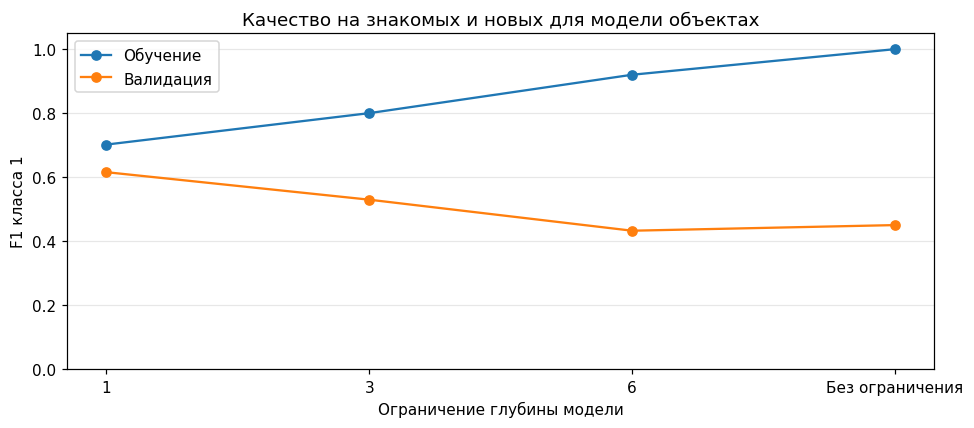

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(depth_results['Ограничение глубины'], depth_results['F1: обучение'], marker='o', label='Обучение')
ax.plot(depth_results['Ограничение глубины'], depth_results['F1: валидация'], marker='o', label='Валидация')
ax.set_ylim(0, 1.05)
ax.set_xlabel('Ограничение глубины модели')
ax.set_ylabel('F1 класса 1')
ax.set_title('Качество на знакомых и новых для модели объектах')
ax.grid(axis='y', alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `plt.subplots(...)` создаёт рисунок и одну область `ax`. В `ax.plot(...)` первый столбец задаёт положения по горизонтали, второй — значения по вертикали. `marker='o'` рисует кружки в точках, `label` задаёт имя линии.
- Квадратные скобки после `depth_results` выбирают столбец по названию. Два вызова `plot` добавляют две линии в одну область. Соединение точек помогает читать порядок вариантов; промежуточные глубины не проверялись.
- `set_ylim(0, 1.05)` устанавливает границы вертикальной оси. `set_xlabel`, `set_ylabel` и `set_title` добавляют подписи. `grid(axis='y', alpha=0.3)` рисует полупрозрачную сетку по вертикальным значениям. `legend()` показывает имена линий, `tight_layout()` размещает элементы, `plt.show()` выводит рисунок.

Когда линия обучения поднимается, а валидационная не следует за ней, усложнение не подтверждается качеством на новых объектах. Очень низкие обе линии указывали бы на недостаточное обучение или слабые признаки. У ограниченного варианта качество может быть уже хорошим: сам по себе маленький `max_depth` ещё не доказывает недообучение.

Практические действия зависят от причины. При переобучении проверяют независимость разбиения, ограничивают сложность, улучшают признаки или добавляют подходящие примеры. При недообучении проверяют, хватает ли признакам и модели выразительности. Ни один из этих шагов не гарантирует улучшения без повторной проверки на данных разработки.

## 5. Кросс-валидация: несколько проверок вместо одного разбиения

### Что меняется от шага к шагу

В одиночной валидации вывод зависит от того, какие объекты случайно попали в проверочную часть. При **кросс-валидации** данные разработки делят на несколько частей — **фолдов**. На каждом шаге один фолд используется для проверки, остальные — для обучения. Создаётся и обучается новый экземпляр всей последовательности подготовки и модели. Затем проверочная роль переходит к следующему фолду.

При пяти фолдах получатся пять оценок. Каждый объект dev один раз будет проверочным и несколько раз обучающим. Оценки помогают увидеть чувствительность к разбиению. Это не пять полностью независимых экспериментов: обучающие части перекрываются. Среднее значение не является гарантией качества на любых будущих данных.

Используем **StratifiedKFold**: он старается сохранять доли классов в каждом фолде. Для выбранного числа фолдов в каждом классе должно хватать объектов; в нашем примере их достаточно. Этот способ подходит к принятому предположению о независимых строках. Финальные 80 объектов остаются за пределами процедуры.

Сначала посмотрим, какие размеры имеют пять разбиений внутри dev. Метод разбиения возвращает позиции строк, поэтому ответы будем выбирать через `.iloc`. Для каждой пары частей проверим, что одна и та же позиция не оказалась одновременно обучающей и проверочной.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)
fold_rows = []

for fold_number, (train_positions, valid_positions) in enumerate(cv.split(X_dev, y_dev), start=1):
    assert set(train_positions).isdisjoint(valid_positions)
    held_labels = y_dev.iloc[valid_positions]
    fold_rows.append({
        'Фолд проверки': fold_number,
        'Строк обучения': len(train_positions),
        'Строк проверки': len(valid_positions),
        'Класс 0 в проверке': int((held_labels == 0).sum()),
        'Класс 1 в проверке': int((held_labels == 1).sum()),
    })

display(pd.DataFrame(fold_rows).set_index('Фолд проверки'))

,Строк обучения,Строк проверки,Класс 0 в проверке,Класс 1 в проверке
Фолд проверки,,,,
1,256,64,50,14
2,256,64,50,14
3,256,64,50,14
4,256,64,50,14
5,256,64,49,15


**Разбор кода и результата.**

- `StratifiedKFold(...)` создаёт правило разбиения. `n_splits=5` задаёт пять фолдов, `shuffle=True` включает перемешивание до разбиения, `random_state=23` делает его воспроизводимым. Сам вызов не обучает модель.
- `cv.split(X_dev, y_dev)` выдаёт пары наборов позиций. `enumerate(..., start=1)` добавляет к каждой паре номер, начиная с единицы. В записи цикла скобки `(train_positions, valid_positions)` распаковывают вложенную пару; снаружи извлекается её номер.
- `assert set(...).isdisjoint(...)` проверяет отсутствие общих позиций. `y_dev.iloc[valid_positions]` выбирает ответы по позиции внутри `y_dev`, а не по исходным идентификаторам. После перемешивания эти два вида обращения различаются: `.loc` выбирает по метке индекса, `.iloc` — по месту в текущем порядке.
- `len(...)` считает строки. Сравнения `held_labels == 0` и `== 1` отмечают классы, `sum()` считает отмеченные строки, `int(...)` получает обычные целые числа. `.append({...})` накапливает строки в списке.
- `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` создают и показывают обзор.

В каждой проверочной части 64 объекта, в соответствующей обучающей — 256. Число объектов класса 1 может немного различаться из-за целочисленного распределения. Стратификация сохраняет состав классов примерно, но не устраняет шум и не решает проблему связанных объектов.

Оценим один фиксированный вариант глубины на всех пяти разбиениях. Передадим в `cross_validate` необученный `Pipeline`, чтобы заполнение пропусков и модель заново обучались только на обучающей части каждого шага. Сохраним обученные экземпляры — чуть позже это позволит проверить состояние заполнения пропусков.

In [16]:
f1_scorer = make_scorer(f1_score, pos_label=1, zero_division=0)
cv_pipeline = Pipeline([
    ('fill', SimpleImputer(strategy='median')),
    ('model', DecisionTreeClassifier(max_depth=3, random_state=42)),
])

cv_result = cross_validate(
    cv_pipeline,
    X_dev,
    y_dev,
    cv=cv,
    scoring={'f1': f1_scorer, 'balanced_accuracy': 'balanced_accuracy'},
    return_train_score=True,
    return_estimator=True,
    n_jobs=1,
)

cv_scores = pd.DataFrame({
    'Фолд': range(1, 6),
    'F1: обучение': cv_result['train_f1'],
    'F1: проверочный фолд': cv_result['test_f1'],
    'Balanced accuracy: проверочный фолд': cv_result['test_balanced_accuracy'],
}).set_index('Фолд')
display(cv_scores)

,F1: обучение,F1: проверочный фолд,Balanced accuracy: проверочный фолд
Фолд,,,
1,0.759,0.429,0.634
2,0.755,0.600,0.751
3,0.732,0.690,0.807
4,0.731,0.455,0.649
5,0.759,0.593,0.726


**Разбор кода и результата.**

- `make_scorer(f1_score, ...)` превращает функцию метрики в объект оценки для процедур scikit-learn. `f1_score` передаётся **без круглых скобок**, то есть как сама функция, которую вызовут позднее. Параметры `pos_label=1`, `zero_division=0` закрепляют наши прежние правила.
- `Pipeline`, `SimpleImputer` и `DecisionTreeClassifier` создают новую необученную последовательность; `max_depth=3` здесь фиксирован для демонстрации. `cross_validate(...)` сам создаёт отдельные экземпляры и вызывает обучение на каждом разбиении. Предварительно вызывать `cv_pipeline.fit(X_dev, y_dev)` не требуется.
- `cv=cv` передаёт правило разбиения. Словарь `scoring` задаёт два показателя: для F1 передан подготовленный объект, для balanced accuracy — библиотечное имя. `return_train_score=True` добавляет оценки на обучении, `return_estimator=True` сохраняет обученные экземпляры, `n_jobs=1` запускает работу последовательно.
- Результат — словарь `cv_result`. Ключи `train_f1`, `test_f1`, `test_balanced_accuracy` выбраны библиотекой. **Слово `test` здесь означает проверочный фолд внутри dev, а не наш финальный набор `X_final`.** В заголовках таблицы эта роль названа явно.
- `range(1, 6)` задаёт пять номеров. `pd.DataFrame(...)` собирает массивы оценок в столбцы; `.set_index('Фолд')` задаёт индекс, `display(...)` показывает результаты.

Пять строк относятся к одной настройке модели на пяти разбиениях. Различие оценок показывает, что одно случайное разбиение могло дать более оптимистичное или более пессимистичное впечатление. Кросс-валидация не исправляет переобучение автоматически: она помогает его обнаружить и сравнивать варианты.

Сведём пять оценок к среднему, минимуму и максимуму для каждого столбца. Среднее удобно для краткого сравнения одинаково проверенных вариантов; крайние значения показывают наблюдавшийся разброс. Полную таблицу отдельных фолдов при этом сохраняем.

In [17]:
cv_summary = cv_scores.agg(['mean', 'min', 'max']).rename(index={
    'mean': 'Среднее',
    'min': 'Минимум',
    'max': 'Максимум',
})
display(cv_summary)

,F1: обучение,F1: проверочный фолд,Balanced accuracy: проверочный фолд
Среднее,0.747,0.553,0.713
Минимум,0.731,0.429,0.634
Максимум,0.759,0.690,0.807


**Разбор кода и результата.**

- `cv_scores.agg([...])` применяет перечисленные способы обобщения к каждому числовому столбцу. Строка `mean` означает среднее, `min` — минимальное значение, `max` — максимальное. Для пяти фолдов одинакового размера такое среднее — удобная краткая характеристика результатов.
- `.rename(index={...})` заменяет имена строк по словарю. Это цепочка вызовов: результат `agg(...)` сразу передаётся следующему методу. `display(...)` выводит итог.

Минимум и максимум относятся только к этим пяти фолдам. Их диапазон не является доверительным интервалом и не обещает, что будущая оценка попадёт внутрь. Средняя F1 по фолдам также не обязана совпасть с F1, посчитанной по объединённым предсказаниям: это разные способы обобщения.

Случайное перемешивание полезно для воспроизводимости, но нельзя многократно менять `random_state`, оставлять самый красивый результат и называть его обычной проверкой. Это тоже выбор по проверочным результатам.

Для показанного варианта средняя F1 проверочных фолдов равна примерно 0,553; отдельные значения лежат от 0,429 до 0,690. Такой разброс объясняет, почему одного разбиения недостаточно для уверенного сравнения близких вариантов.

### Почему предобработка должна оставаться внутри проверки

Заполнение пропусков, масштабирование и отбор признаков могут извлекать сведения из данных при `fit`. Если обучить их на всём dev до кросс-валидации, проверочные объекты уже повлияют на подготовку. Даже если ответы явно не передавались, оценка перестанет соответствовать сценарию полностью новых данных.

Правильная последовательность на каждом шаге: разделить строки, обучить подготовку только на обучающих строках, преобразовать обе части с её сохранёнными настройками, обучить модель, получить и оценить предсказания проверочного фолда. `Pipeline` в предыдущем примере обеспечивает именно такой порядок. Любые решения, использующие ответы, также должны оставаться внутри обучения соответствующего шага.

Заглянем в пять сохранённых последовательностей и прочитаем значение для заполнения первого сигнала. Это диагностический просмотр уже обученных объектов. В библиотеке атрибуты, появившиеся после обучения, часто оканчиваются подчёркиванием.

In [18]:
fill_rows = []
for fold_number, fitted_pipeline in enumerate(cv_result['estimator'], start=1):
    learned_value = fitted_pipeline.named_steps['fill'].statistics_[0]
    fill_rows.append({
        'Фолд проверки': fold_number,
        'Значение заполнения signal_1': learned_value,
    })

display(pd.DataFrame(fill_rows).set_index('Фолд проверки'))

,Значение заполнения signal_1
Фолд проверки,
1,-0.027
2,-0.031
3,-0.099
4,-0.067
5,-0.028


**Разбор кода и результата.**

- `cv_result['estimator']` выбирает сохранённые обученные последовательности. `enumerate(..., start=1)` нумерует их; `for` перебирает номер и соответствующий `fitted_pipeline`.
- `.named_steps` предоставляет доступ к шагам по именам. `['fill']` выбирает обученный `SimpleImputer`. Его атрибут `.statistics_` содержит значения заполнения для всех входных признаков; `[0]` выбирает первый столбец — `signal_1`. Здесь значение только читается, повторного обучения нет.
- `.append({...})` накапливает словари, `pd.DataFrame(...)` собирает таблицу, `.set_index(...)` задаёт индекс и `display(...)` показывает её.

Значения могут различаться, потому что каждый экземпляр видел свою обучающую часть. Их совпадение тоже было бы допустимо и само по себе не доказывало бы утечку. Правильность обеспечивается порядком обучения внутри `cross_validate`, а просмотр состояния помогает понять, что подготовка является частью обучаемой последовательности.

## 6. Когда случайные фолды не подходят

### Повторяющиеся объекты: разделение по группам

Если от одного клиента поступило несколько обращений, строки связаны. Когда цель — работа **с новыми клиентами**, обращения одного клиента должны оставаться по одну сторону границы. Иначе модель может узнать особенности знакомого клиента и получить завышенную оценку переноса на незнакомых.

**GroupKFold** разделяет группы так, чтобы в одном разбиении одна группа не встречалась одновременно в обучении и проверке. Группу задаёт отдельный массив идентификаторов; это информация для разбиения, её не обязательно подавать модели как признак. Такой способ сам по себе не сохраняет доли классов и не учитывает хронологию. Если цель другая — например, будущие обращения уже известных клиентов, — правило проверки нужно согласовать с этой целью.

Рассмотрим 12 обращений от четырёх клиентов, по три обращения от каждого. Обучать модель здесь не нужно: покажем только границы трёх разбиений. Для каждого шага перечислим клиентов обеих частей и проверим, что они не пересекаются.

In [19]:
client_ids = np.array(['Клиент А'] * 3 + ['Клиент Б'] * 3 + ['Клиент В'] * 3 + ['Клиент Г'] * 3)
group_features = pd.DataFrame({'Номер обращения': range(1, 13)})
group_cv = GroupKFold(n_splits=3)
group_rows = []

for fold_number, (train_positions, valid_positions) in enumerate(
    group_cv.split(group_features, groups=client_ids), start=1
):
    train_clients = set(client_ids[train_positions])
    valid_clients = set(client_ids[valid_positions])
    assert train_clients.isdisjoint(valid_clients)
    group_rows.append({
        'Фолд': fold_number,
        'Клиенты обучения': ', '.join(sorted(train_clients)),
        'Клиенты проверки': ', '.join(sorted(valid_clients)),
        'Строк обучения': len(train_positions),
        'Строк проверки': len(valid_positions),
    })

display(pd.DataFrame(group_rows).set_index('Фолд'))

,Клиенты обучения,Клиенты проверки,Строк обучения,Строк проверки
Фолд,,,,
1,"Клиент Б, Клиент В","Клиент А, Клиент Г",6,6
2,"Клиент А, Клиент Б, Клиент Г",Клиент В,9,3
3,"Клиент А, Клиент В, Клиент Г",Клиент Б,9,3


**Разбор кода и результата.**

- `np.array(...)` создаёт массив идентификаторов. Повторение списков через `*` и соединение через `+` дают три соседние строки для каждого клиента. `pd.DataFrame(...)` создаёт простую таблицу, `range(1, 13)` — 12 номеров.
- `GroupKFold(n_splits=3)` создаёт правило трёх разбиений. В `split(..., groups=client_ids)` передаётся отдельный идентификатор группы для каждой строки. Правильные ответы здесь не нужны: демонстрируем только состав частей.
- `enumerate(..., start=1)` добавляет номер; цикл извлекает его и пару позиций. `client_ids[train_positions]` и `[valid_positions]` выбирают клиентов по позициям. `set(...)` оставляет уникальные имена; `assert ...isdisjoint(...)` требует отсутствия пересечения.
- `sorted(...)` упорядочивает имена для удобного чтения. `', '.join(...)` соединяет строки с запятой и пробелом. `len(...)` считает строки, `.append({...})` накапливает описание.
- `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` показывают результат.

У частей может быть разное число строк: группы остаются целиком. Проверка подтверждает отсутствие общих клиентов внутри каждого разбиения, но не говорит о качестве модели. Для рабочей оценки это правило передали бы в `cross_validate` вместе с соответствующей информацией о группах.

### Временные данные: обучение на прошлом

Если модель должна работать с будущими событиями, случайное перемешивание может дать ей информацию из будущего относительно проверяемых строк. В таком сценарии проверка должна идти позже обучения по времени.

**TimeSeriesSplit** делает последовательные разбиения: обучающая часть растёт, а проверочная располагается дальше по порядку. Он ориентируется на порядок строк, поэтому сначала данные нужно хронологически отсортировать. В примере даты идут с одинаковым шагом. Для реальных нерегулярных событий границы периодов часто задают отдельно. Если ответы созревают с задержкой или соседние события тесно связаны, дополнительно оставляют промежуток между обучением и проверкой; его длина зависит от задачи.

Создадим 12 последовательных дат и выведем временные границы трёх разбиений. Явно отсортируем таблицу по дате и проверим, что последняя обучающая дата меньше первой проверочной. Это пример организации проверки, без обучения прогнозной модели.

In [20]:
time_data = pd.DataFrame({
    'Дата': pd.date_range('2026-01-01', periods=12, freq='D'),
    'Условный сигнал': range(12),
}).sort_values('Дата').reset_index(drop=True)
time_cv = TimeSeriesSplit(n_splits=3)
time_rows = []

for fold_number, (train_positions, valid_positions) in enumerate(time_cv.split(time_data), start=1):
    train_dates = time_data.iloc[train_positions]['Дата']
    valid_dates = time_data.iloc[valid_positions]['Дата']
    assert train_dates.max() < valid_dates.min()
    time_rows.append({
        'Фолд': fold_number,
        'Начало обучения': train_dates.min().strftime('%d.%m.%Y'),
        'Конец обучения': train_dates.max().strftime('%d.%m.%Y'),
        'Начало проверки': valid_dates.min().strftime('%d.%m.%Y'),
        'Конец проверки': valid_dates.max().strftime('%d.%m.%Y'),
    })

display(pd.DataFrame(time_rows).set_index('Фолд'))

,Начало обучения,Конец обучения,Начало проверки,Конец проверки
Фолд,,,,
1,01.01.2026,03.01.2026,04.01.2026,06.01.2026
2,01.01.2026,06.01.2026,07.01.2026,09.01.2026
3,01.01.2026,09.01.2026,10.01.2026,12.01.2026


**Разбор кода и результата.**

- `pd.date_range(...)` создаёт последовательность дат: от указанного начала, `periods=12` — 12 дат, `freq='D'` — шаг один день. `range(12)` даёт числа от 0 до 11. `pd.DataFrame(...)` собирает два столбца.
- `.sort_values('Дата')` сортирует по времени. `.reset_index(drop=True)` заново нумерует строки, не сохраняя прежний индекс отдельным столбцом. В этом искусственном примере порядок уже был правильным, но явный шаг показывает требование к входу.
- `TimeSeriesSplit(n_splits=3)` задаёт три последовательных разбиения. `.split(time_data)` возвращает позиции; `enumerate(..., start=1)` добавляет номер. `.iloc[...]` выбирает строки по позиции, `['Дата']` — столбец дат.
- `max()` и `min()` находят крайние даты. `<` проверяет, что одна дата раньше другой; `assert` останавливает код при нарушении порядка. `.strftime('%d.%m.%Y')` превращает дату в строку формата «день.месяц.год»; специальные обозначения `%d`, `%m`, `%Y` задают части даты.
- `.append({...})`, `pd.DataFrame(...)`, `.set_index(...)`, `display(...)` собирают и выводят границы.

Все проверочные периоды идут после соответствующих обучающих. Хорошая оценка при случайных фолдах не заменяет такую проверку, если реальный сценарий — будущее. При сочетании групп и времени ограничения нужно выполнять одновременно; ни один из показанных методов по отдельности не решает все варианты зависимости.

## 7. Выбор настройки и финальная проверка

### Сравнение вариантов на данных разработки

Вернёмся к искусственным независимым объектам. Ранее для наглядности сравнили четыре ограничения глубины на одной валидации. Теперь сравним **те же заранее заданные варианты** по пяти стратифицированным фолдам внутри dev. Одинаковые фолды и метрика делают сравнение понятнее: меняется настройка модели, а не правило оценки.

Настройку, которую задаём до обучения, называют **гиперпараметром**. `GridSearchCV` перебирает указанный список таких настроек и выбирает лучшую по заданной оценке. В отличие от внутренних настроек, полученных методом `fit`, эти варианты определяем мы.

Кросс-валидация также может стать источником переобучения выбора: если бесконечно подбирать варианты под её результаты, максимальная оценка окажется слишком оптимистичной. Поэтому состав проверки и небольшой список кандидатов фиксируются заранее, а финальная отложенная часть нужна после завершения выбора. В более сложных исследованиях применяют вложенную проверку, но для этого учебного примера достаточно отдельного финального набора.

Проведём поиск по четырём значениям глубины. При пяти фолдах это 20 небольших обучений для сравнения, после чего выбранный вариант автоматически обучится на всём dev. Финальная часть в вызов `fit` не передаётся.

In [21]:
search_pipeline = Pipeline([
    ('fill', SimpleImputer(strategy='median')),
    ('model', DecisionTreeClassifier(random_state=42)),
])
search = GridSearchCV(
    estimator=search_pipeline,
    param_grid={'model__max_depth': depth_options},
    scoring=f1_scorer,
    cv=cv,
    refit=True,
    return_train_score=True,
    n_jobs=1,
)
search.fit(X_dev, y_dev)
print('Сравнение вариантов завершено. Финальная часть ещё не оценивалась.')

Сравнение вариантов завершено. Финальная часть ещё не оценивалась.


**Разбор кода и результата.**

- `Pipeline` снова объединяет `SimpleImputer` и `DecisionTreeClassifier`. У нового дерева глубина пока не указана: её задаст поиск. `random_state=42` фиксирует случайные решения алгоритма.
- `GridSearchCV(...)` получает необученную последовательность через `estimator`. Словарь `param_grid` задаёт перебираемый параметр. В строке `'model__max_depth'` часть `model` — имя шага, два подчёркивания отделяют его от параметра `max_depth`. `depth_options` содержит ровно четыре варианта из предыдущего сравнения.
- `scoring=f1_scorer` выбирает F1 класса 1 по нашему соглашению, `cv=cv` — прежние пять фолдов. `return_train_score=True` сохраняет качество обучения для диагностики, `n_jobs=1` ограничивает работу одним процессом.
- `refit=True` означает: после выбора лучшей настройки автоматически обучить её заново на всех данных, переданных в `search.fit(...)`. Здесь это только `X_dev`, `y_dev`. Заполнение пропусков при сравнении обучается внутри каждого фолда, а при итоговом переобучении — на всём dev.
- `fit(...)` запускает сравнение и итоговое обучение, `print(...)` сообщает о завершении. Финальные правильные ответы не использованы в этих действиях.

Посмотрим сводку кандидатов и сохраним уже обученную выбранную последовательность в отдельной переменной. Рейтинг относится к среднему F1 проверочных фолдов. Даже лучшую строку этой таблицы нельзя выдавать за результат на финальной части.

In [22]:
search_results = pd.DataFrame(search.cv_results_)
search_table = search_results[[
    'param_model__max_depth', 'mean_train_score', 'mean_test_score', 'rank_test_score'
]].rename(columns={
    'param_model__max_depth': 'Глубина: None — без ограничения',
    'mean_train_score': 'Средний F1: обучение',
    'mean_test_score': 'Средний F1: проверочные фолды',
    'rank_test_score': 'Место по проверочным фолдам',
}).sort_values('Место по проверочным фолдам')
display(search_table)

selected_model = search.best_estimator_
print('Зафиксированная настройка:', search.best_params_)
print('Средний F1 выбранного варианта на фолдах:', round(search.best_score_, 3))
print('Подготовка и модель уже обучены на всех', len(X_dev), 'объектах dev.')

,Глубина: None — без ограничения,Средний F1: обучение,Средний F1: проверочные фолды,Место по проверочным фолдам
0,1,0.685,0.634,1
1,3,0.747,0.553,2
2,6,0.925,0.521,3
3,None,1.000,0.505,4


Зафиксированная настройка: {'model__max_depth': 1}
Средний F1 выбранного варианта на фолдах: 0.634
Подготовка и модель уже обучены на всех 320 объектах dev.


**Разбор кода и результата.**

- `search.cv_results_` — словарь результатов поиска, доступный после `fit`. Завершающее подчёркивание отмечает обученное состояние. `pd.DataFrame(...)` превращает его в таблицу.
- `search_results[[...]]` выбирает список столбцов; внутренние скобки создают список, внешние обращаются к таблице. `param_model__max_depth` содержит вариант настройки, `mean_train_score` — среднее качество на обучении, `mean_test_score` — среднее на проверочных фолдах. Как и раньше, `test` в служебных ключах не означает наш финальный набор.
- `.rename(columns={...})` даёт понятные заголовки, `.sort_values(...)` упорядочивает по месту: 1 — лучший результат. При равной оценке несколько строк могут иметь одно место. `display(...)` показывает таблицу.
- `search.best_estimator_` — уже заново обученный на всём dev выбранный `Pipeline`. Присваивание сохраняет ссылку на него в `selected_model`; это не новое обучение. `best_params_` — выбранные настройки, `best_score_` — средний F1 выбранного варианта внутри поиска. `round(..., 3)` округляет вывод; `len(X_dev)` считает строки; `print(...)` печатает сведения.

Зафиксированы подготовка, настройка модели, способ предсказания и основной критерий F1. Строка победителя выбрана по тем же оценкам, которые показаны в таблице, поэтому её среднее может быть оптимистичным. Независимая финальная оценка будет отдельным результатом. Если позже поменять модель по финальным ошибкам, прежняя финальная часть превратится в данные разработки и для новой независимой оценки потребуется другой материал.

В нашем выполнении выбрана глубина 1: средний проверочный F1 около 0,634 против 0,505 у модели без ограничения. Победил наиболее ограниченный из проверенных вариантов. Это вывод о данном наборе и списке кандидатов, а не правило, что самая простая модель всегда лучше.

### Один финальный набор после завершения выбора

Теперь применим зафиксированную последовательность к ранее отложенным 80 объектам. `predict` будет пользоваться заполнением пропусков, выученным на dev. На финальной части не вызывается `fit` и не выбирается порог.

Покажем несколько метрик и матрицу ошибок для **одних и тех же сохранённых предсказаний**. Это одна проверка, а не повторный выбор модели. Финальная F1 может отличаться от среднего по фолдам: здесь другой набор объектов и модель обучалась на большем числе строк. Небольшой набор даёт ограниченную точность оценки; скрывать невыгодный результат или подбирать разбиение заново нельзя.

Получим финальные классы один раз и посчитаем знакомые показатели. Дополнительно возьмём оценки класса 1 для ROC-AUC и AP. Столбец оценок выберем по реальному порядку классов обученной модели, а не по предположению о номере столбца.

In [23]:
final_predictions = selected_model.predict(X_final)
class_order = list(selected_model.named_steps['model'].classes_)
positive_column = class_order.index(1)
final_scores = selected_model.predict_proba(X_final)[:, positive_column]

final_metrics = classification_metrics(y_final, final_predictions)
final_metrics['ROC-AUC'] = roc_auc_score(y_final, final_scores)
final_metrics['Average Precision (AP)'] = average_precision_score(y_final, final_scores)
display(pd.DataFrame([final_metrics], index=['Финальная отложенная часть']))
print('Объектов в финальной проверке:', len(y_final))

,Accuracy,Precision (класс 1),Recall (класс 1),F1 (класс 1),Balanced accuracy,ROC-AUC,Average Precision (AP)
Финальная отложенная часть,0.838,0.619,0.722,0.667,0.797,0.797,0.51


Объектов в финальной проверке: 80


**Разбор кода и результата.**

- `selected_model.predict(X_final)` последовательно применяет сохранённое заполнение пропусков и модель, возвращая классы. Здесь нет вызова обучения. `final_predictions` сохраняет ответы для всей последующей финальной диагностики.
- `.named_steps['model'].classes_` содержит порядок классов обученного дерева. `list(...)` превращает его в обычный список, `.index(1)` находит позицию класса 1 в нём. Это имя метода списка; оно отличается от атрибута индекса таблицы Pandas.
- `predict_proba(X_final)` возвращает таблицу оценок: строки — объекты, столбцы — классы в указанном порядке. Запись `[:, positive_column]` выбирает все строки (`:`) и один нужный столбец. У дерева такие оценки могут быть грубыми; мы не считаем их автоматически надёжными вероятностями.
- `classification_metrics(...)` считает показатели готовых классов. `roc_auc_score(...)` и `average_precision_score(...)` используют отдельный массив оценок `final_scores`. Запись `final_metrics['ROC-AUC'] = ...` добавляет элемент в словарь; аналогично добавляется AP.
- `pd.DataFrame([final_metrics], index=[...])` создаёт именованную строку; `display(...)` выводит её. `len(...)` считает проверочные объекты, `print(...)` сообщает их количество.

Основной результат выбора — F1 класса 1 в этой строке, дополненный precision, recall и другими показателями. Он относится к данным этого примера. Итог может оказаться как выше, так и ниже среднего по кросс-валидации: это не повод корректировать настройку на тех же финальных ответах. Самая высокая метрика в строке не становится основным критерием задним числом.

На сохранённой финальной проверке F1 равна примерно 0,667, precision — 0,619, recall — 0,722. Значит, найдено около 72% нужных проверок, а среди назначенных проверок примерно 62% действительно нужны. Accuracy около 0,838 описывает другой аспект: долю всех верных классов.

Разложим финальные ошибки по типам и посмотрим их расположение в матрице. Используем уже полученные `final_predictions`; повторно выбирать модель или получать новые варианты ответов не будем. Так числовые метрики связываются с конкретными пропусками и лишними проверками.

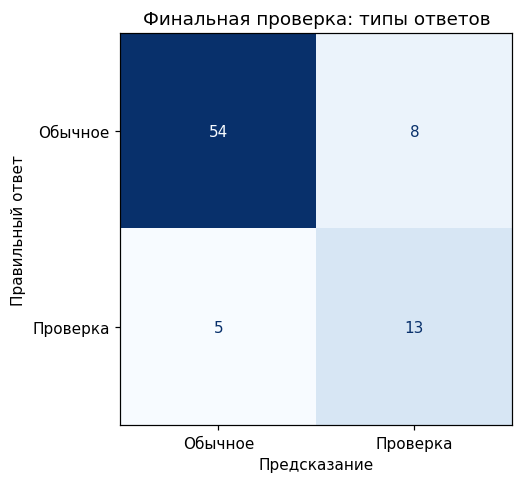

Лишние проверки: 8
Пропущенные проверки: 5


In [24]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_final,
    final_predictions,
    labels=[0, 1],
    display_labels=['Обычное', 'Проверка'],
    cmap='Blues',
    colorbar=False,
    ax=ax,
)
ax.set_title('Финальная проверка: типы ответов')
ax.set_xlabel('Предсказание')
ax.set_ylabel('Правильный ответ')
fig.tight_layout()
plt.show()

print('Лишние проверки:', int(((y_final == 0) & (final_predictions == 1)).sum()))
print('Пропущенные проверки:', int(((y_final == 1) & (final_predictions == 0)).sum()))

**Разбор кода и результата.**

- `plt.subplots(...)` создаёт рисунок и область рисования. `ConfusionMatrixDisplay.from_predictions(...)` использует правильные ответы и сохранённые классы. `labels=[0, 1]` и `display_labels` сохраняют тот же порядок клеток, что и в начале файла; `cmap`, `colorbar`, `ax` управляют видом и местом рисунка.
- `set_title`, `set_xlabel`, `set_ylabel` подписывают его, `tight_layout()` размещает элементы, `plt.show()` выводит результат.
- `(y_final == 0) & (final_predictions == 1)` отмечает лишние проверки; второй набор условий — пропущенные проверки. Порядок массива предсказаний соответствует порядку `y_final`, поскольку они относятся к одному `X_final`. `sum()` считает совпадения условий, `int(...)` получает целое число, `print(...)` печатает его.

Верхняя правая клетка — лишние проверки, нижняя левая — пропущенные. Их нельзя оценивать только по сумме: для реального процесса последствия различаются. Разбор финальных ошибок позволяет описать ограничения проверенного варианта. Новые изменения по этому разбору начинают новый цикл разработки с новой независимой финальной проверкой.

Конкретные числа на матрице: 54 верных обычных ответа, 13 найденных нужных проверок, 8 лишних проверок и 5 пропусков. Всего это 80 объектов. Эти четыре числа позволяют восстановить смысл показанных бинарных метрик и оценить нагрузку на процесс проверки.

## 8. Как связаны изученные действия

Получить числовую метрику и получить заслуживающую доверия оценку — разные по объёму работы шаги. Для оценки нужен подходящий сценарий проверки.

1. **Определить ответ и тип ошибки.** Указать положительный класс для классификации, единицы ответа для регрессии и последствия промахов.
2. **Зафиксировать критерий.** Выбрать основной показатель до сравнения кандидатов; дополнительные показатели нужны для понимания, а не для поиска самого красивого числа.
3. **Разделить данные по сценарию применения.** Независимые объекты допускают случайные фолды; новые клиенты требуют границы по группам, будущие события — по времени.
4. **Получить простой ориентир.** Сравнить модель с baseline на таких же проверочных объектах.
5. **Сопоставить обучение и валидацию.** Проверить, не скрывается ли за хорошим обучающим результатом переобучение, и не остаётся ли качество слабым на обеих частях.
6. **Проверить кандидатов внутри dev.** Обучать всю подготовку вместе с моделью отдельно в каждом фолде. Сохранять отдельные оценки и их обобщение.
7. **Завершить выбор до финальной оценки.** Применить зафиксированную последовательность к отложенным объектам, описать результат и ограничения.

Кросс-валидация отвечает на вопрос о качестве в выбранной схеме разбиения. Она не исправляет неверные метки, отсутствие нужных признаков, утечку будущей информации или отличие будущих объектов от учебных. Метрика приобретает смысл вместе с описанием данных и проверки.

### Справочные страницы

Для уточнения названий параметров и правил вычисления доступны официальные страницы scikit-learn: [метрики качества](https://scikit-learn.org/1.8/modules/model_evaluation.html), [кросс-валидация и способы разбиения](https://scikit-learn.org/1.8/modules/cross_validation.html), [GridSearchCV](https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.GridSearchCV.html). Это дополнительные справочные ссылки; для чтения и выполнения ноутбука они не требуются. Версия установленной библиотеки указана в выводе первой ячейки.